# Week 1 — Graph profiling

**AXIOM Pricing Module · Pricing Engine & MLOps**

Purpose: understand the data before building anything on it. Counts, distributions,
null rates, referential integrity — plus two pricing-specific questions the Data
Contract does not answer:

1. What do `gross_amount` and `net_amount` actually mean in this graph?
2. Can we even build a waterfall — is there a list price and a cost for every line?

> Neo4j credentials have not arrived yet, so this runs on the synthetic CSV snapshot.
> Set `PRICING_SOURCE=neo4j` in `.env` and re-run this notebook unchanged when they do.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import pandas as pd
import matplotlib.pyplot as plt

from pricing import profiling, gross_to_net
from pricing.data_source import get_source

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

src = get_source()
src.snapshot_info()

{'backend': 'csv',
 'location': '/sessions/confident-brave-curie/mnt/data/synthetic',
 'read_at': '2026-08-05T12:51:45.029450+00:00',
 'content_sha256': '6af98ff70daf16a190620736a6b51ef4dd25cd0c2ef65887448b348d15e33e61'}

## 1. Shape of the graph

How much of everything is there?

In [2]:
counts = profiling.table_counts(src)
counts

,table,rows,columns
0,transaction_discounts,1997,3
1,transaction_lines,1408,5
2,transactions,700,9
3,customers,40,9
4,products,24,7
5,discounts,8,8
6,regions,6,5
7,channels,5,4


Node labels map to `customers`, `products`, `discounts`, `channels`, `regions`, `transactions`.
The two large tables are *relationship* tables — `transaction_lines` is `CONTAINS`
(with quantity / unit_price / line_total on the edge) and `transaction_discounts`
is `DISCOUNTED_BY` (with discount_amount_applied on the edge). The pricing signal
lives on the edges, not the nodes.

In [3]:
src.transactions().head()

,transaction_id,date,customer_id,channel_id,gross_amount,net_amount,quantity,unit_price,payment_terms
0,TRX-00001,2026-03-31,CUS-021,CH-ONL,"59,440.02","56,694.43",55,"1,080.73",NET90
1,TRX-00002,2025-11-01,CUS-025,CH-RES,"87,316.49","77,886.61",69,"1,265.46",NET90
2,TRX-00003,2025-07-20,CUS-036,CH-DIS,"59,990.47","59,990.47",50,"1,199.81",PREPAY
3,TRX-00004,2025-12-10,CUS-034,CH-ONL,"41,514.73","41,514.73",34,"1,221.02",PREPAY
4,TRX-00005,2025-08-08,CUS-036,CH-OEM,"65,265.00","62,839.42",52,"1,255.10",NET30


In [4]:
src.transaction_lines().head()

,transaction_id,product_id,quantity,unit_price,line_total
0,TRX-00001,PRD-016,26,"1,457.87","37,904.62"
1,TRX-00001,PRD-018,29,742.60,"21,535.40"
2,TRX-00002,PRD-017,40,"1,967.87","78,714.80"
3,TRX-00002,PRD-023,29,296.61,"8,601.69"
4,TRX-00003,PRD-002,29,"1,524.65","44,214.85"


## 2. Referential integrity — are there dangling edges?

An orphan transaction cannot be attributed to a customer, so it would silently distort every aggregate. Check before trusting anything.

In [5]:
profiling.referential_integrity(src)

,check,n_values,n_unresolved,examples,ok
0,transactions.customer_id,700,0,-,True
1,transactions.channel_id,700,0,-,True
2,customers.region_id,40,0,-,True
3,transaction_lines.transaction_id,1408,0,-,True
4,transaction_lines.product_id,1408,0,-,True
5,transaction_discounts.transaction_id,1997,0,-,True
6,transaction_discounts.discount_id,1997,0,-,True
7,transactions with >=1 CONTAINS line,700,0,-,True


## 3. Null rates

Every null is a decision the waterfall will have to make later. Listing them is the point of Week 1.

In [6]:
profiling.null_summary(src)

,table,column,dtype,n_rows,n_null,null_rate_pct,n_unique
0,discounts,amount,float64,8,8,100.00,0
1,products,unit_cost,float64,24,2,8.33,22
2,customers,industry,object,40,2,5.00,6
3,products,list_price,float64,24,1,4.17,23
4,transactions,payment_terms,object,700,21,3.00,5
5,customers,tenure_years,float64,40,1,2.50,16
6,transactions,net_amount,float64,700,11,1.57,689
7,transaction_discounts,discount_amount_applied,float64,1997,11,0.55,1837


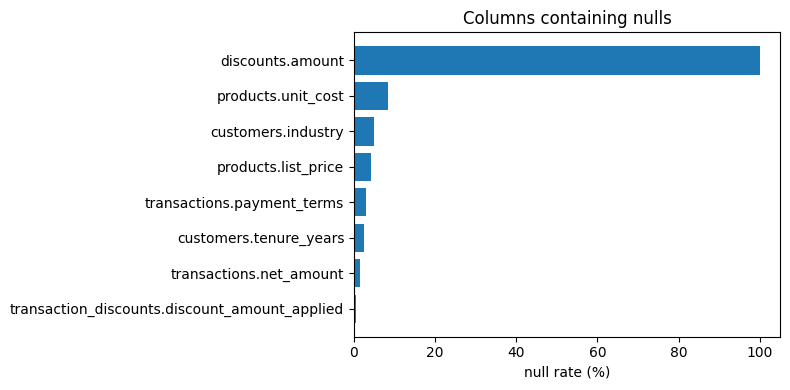

In [7]:
nr = profiling.null_rates(src)
sub = nr[nr.n_null > 0].sort_values("null_rate_pct")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([f"{r.table}.{r.column}" for r in sub.itertuples()], sub.null_rate_pct)
ax.set_xlabel("null rate (%)"); ax.set_title("Columns containing nulls")
plt.tight_layout(); plt.show()

Read these as follows:

- `discounts.amount` is 100% null — this catalogue is entirely **rate**-based. Not a
  defect; the `amount` column is simply unused. Worth confirming that the real graph
  behaves the same, because a mixed rate/amount catalogue would need different handling.
- `products.list_price` / `unit_cost` nulls are the expensive ones: they break the
  *top* and the *bottom* of the waterfall for every transaction touching those products.
- `transaction_discounts.discount_amount_applied` nulls mean a discount was applied but
  we do not know how much → leakage is understated → that transaction is not certifiable.
- `customers.industry`, `tenure_years`, `transactions.payment_terms` are segmentation
  features (Week 5), not waterfall inputs. Note and move on.

## 4. Distributions

In [8]:
profiling.numeric_profile(src)

,table,column,n,mean,std,min,p25,median,p75,max,n_negative,n_zero
0,transactions,gross_amount,700,"54,908.37","53,852.29",267.54,"14,346.38","38,024.18","76,176.46","303,470.46",0,0
1,transactions,net_amount,689,"53,048.29","51,239.15",267.54,"14,096.81","37,330.50","74,523.92","303,470.46",0,0
2,transactions,quantity,700,50.18,45.59,2.00,14.00,36.50,70.25,256.00,0,0
3,transactions,unit_price,700,"1,120.85",468.03,83.15,784.24,"1,138.02","1,464.57","2,284.12",0,0
4,transaction_lines,quantity,1408,24.95,20.50,2.00,8.00,20.00,35.00,132.00,0,0
5,transaction_lines,unit_price,1408,"1,117.22",614.10,76.07,643.46,"1,178.59","1,623.19","2,302.92",0,0
6,transaction_lines,line_total,1408,"27,298.20","28,381.96",261.99,"6,605.68","17,934.07","38,148.97","208,723.68",0,0
7,transaction_discounts,discount_amount_applied,1986,"3,257.06","6,073.14",0.00,160.03,905.29,"3,498.89","52,913.42",0,144
8,discounts,rate,8,4.81,3.56,1.50,2.38,3.75,5.75,12.00,0,0
9,customers,tenure_years,39,8.56,4.98,1.00,4.50,8.00,13.50,17.00,0,0


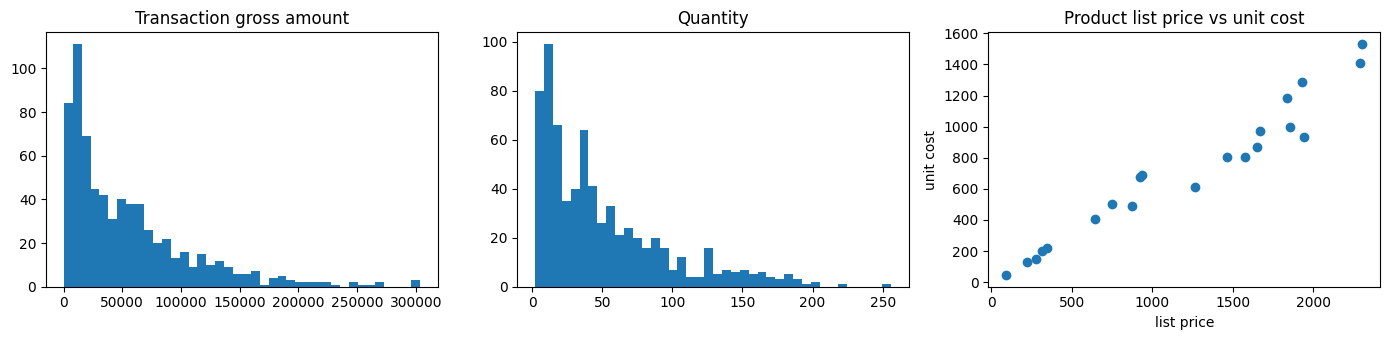

In [9]:
txn = src.transactions()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(txn.gross_amount, bins=40); axes[0].set_title("Transaction gross amount")
axes[1].hist(txn.quantity, bins=40);     axes[1].set_title("Quantity")
prod = src.products()
axes[2].scatter(prod.list_price, prod.unit_cost); axes[2].set_xlabel("list price"); axes[2].set_ylabel("unit cost")
axes[2].set_title("Product list price vs unit cost")
plt.tight_layout(); plt.show()

In [10]:
profiling.categorical_profile(src)

,table,column,value,n,pct
0,transactions,channel_id,CH-RES,168,24.00
1,transactions,channel_id,CH-ONL,149,21.29
2,transactions,channel_id,CH-DIR,131,18.71
3,transactions,channel_id,CH-DIS,128,18.29
4,transactions,channel_id,CH-OEM,124,17.71
...,...,...,...,...,...
125,regions,country,FR,1,16.67
126,regions,country,GB,1,16.67
127,regions,country,PL,1,16.67
128,regions,country,AE,1,16.67


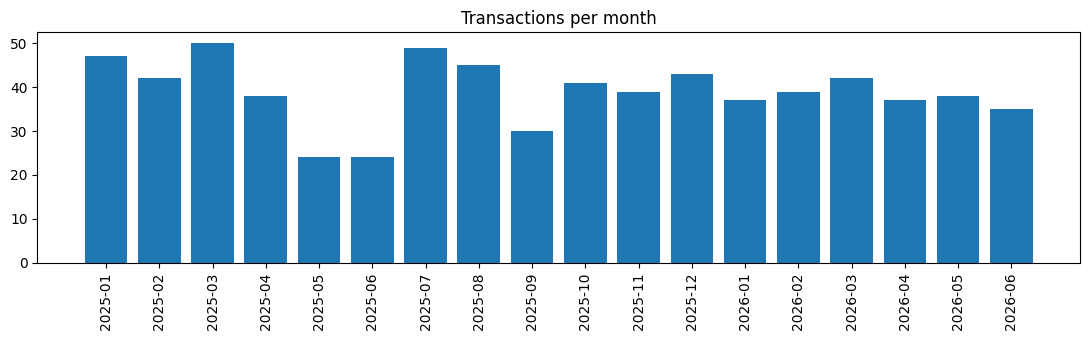

,month,n_transactions,gross_amount
0,2025-01,47,"2,825,824.96"
1,2025-02,42,"2,412,386.56"
2,2025-03,50,"2,500,956.43"
3,2025-04,38,"1,833,263.09"
4,2025-05,24,"1,800,300.66"
5,2025-06,24,"1,296,812.76"
6,2025-07,49,"2,275,042.84"
7,2025-08,45,"2,701,827.73"
8,2025-09,30,"1,372,017.54"
9,2025-10,41,"1,920,569.25"


In [11]:
dp = profiling.date_profile(src)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(dp.month, dp.n_transactions)
ax.set_title("Transactions per month"); plt.xticks(rotation=90); plt.tight_layout(); plt.show()
dp

18 months of history, 2025-01 to 2026-06, no future dates. Roughly 700 transactions
across 40 customers — around 17 deals per customer. **Keep that number in mind:** it is
thin for per-segment elasticity (Week 5), which is exactly why the plan mandates
hierarchical shrinkage rather than a per-segment regression.

## 5. The important question: what do `gross_amount` and `net_amount` mean?

The Data Contract lists both fields but does not define them. Four hypotheses,
tested against the data rather than assumed.

In [12]:
profiling.amount_reconciliation(src)

,hypothesis,n_tested,max_abs_diff,mean_abs_diff,n_within_0.01pct,holds
0,H1: gross == sum(line_total),700,0.00,0.00,700,True
1,H2: net == gross - on-invoice,689,"58,315.74","4,820.84",11,False
2,H3: net == gross - all discounts,689,"63,161.43","6,947.87",21,False
3,H4: net == gross - off-invoice,689,0.00,0.00,689,True


**Finding.** `gross_amount` is exactly the sum of the `CONTAINS` line totals (H1 holds
to floating-point precision — good, the header and the lines agree).

But `net_amount` equals `gross_amount − OFF-invoice discounts` (H4 holds exactly),
**not** gross minus on-invoice discounts (H2 fails, mean error ≈ €4.8k per transaction).

That is the opposite of the usual convention, where "net"/invoice price is what appears
on the invoice, i.e. after on-invoice discounts and before off-invoice leakage.

**Consequence for the engine:** do not use `net_amount` as a waterfall step. Compute every
step from the `DISCOUNTED_BY` edges and the discount type, which is unambiguous. `net_amount`
is carried through for reconciliation only. **Question for the mentor at the Week 2 gate.**

## 6. Can we build a waterfall at all?

The waterfall starts at list price, which lives on `Product`, not on the transaction.

In [13]:
profiling.list_price_coverage(src)

,metric,n,pct
0,transaction lines,1408,100.00
1,lines with a product list_price,1348,95.74
2,lines with a product unit_cost,1292,91.76
3,lines fully decomposable (list + cost),1232,87.50
4,lines priced ABOVE list (unit_price > list_price),0,0.00


In [14]:
profiling.discount_coverage(src)

,discount_id,type,category,rate,n_applications,n_transactions,n_amount_missing,total_amount,mean_amount,pct_of_transactions
0,DSC-ON-VOL,on-invoice,Volume tier,8.00,335,335,0,"1,665,324.45","4,971.12",47.90
1,DSC-ON-PRM,on-invoice,Promotional,5.00,372,372,0,"1,659,516.90","4,461.07",53.10
2,DSC-ON-CTR,on-invoice,Contract price,12.00,319,319,0,"1,477,331.77","4,631.13",45.60
3,DSC-OFF-SPA,off-invoice,Special agreement,3.50,186,186,1,"380,485.39","2,056.68",26.60
4,DSC-OFF-REB,off-invoice,Annual volume rebate,4.00,179,179,5,"360,438.07","2,071.48",25.60
5,DSC-OFF-TRM,off-invoice,Payment terms cost,2.00,195,195,1,"352,369.79","1,816.34",27.90
6,DSC-OFF-FRT,off-invoice,Freight allowance,1.50,216,216,3,"308,414.21","1,447.95",30.90
7,DSC-OFF-COP,off-invoice,Co-op marketing credit,2.50,195,195,1,"264,640.87","1,364.13",27.90


All eight discount types are in use. Each of the five off-invoice types touches 25-31% of transactions, and together they
reach 79% of the book — this is precisely the "silent, unmanaged leakage" the Brief describes,
and it is why the waterfall must separate on- from off-invoice rather than netting them.

Note the applied amounts do **not** equal the catalogue `rate` × gross: the realised rate
varies per deal. So the rate is a headline, and the edge amount is the truth. Always use
the edge.

## 7. Quick win — gross-to-net for one customer

In [15]:
result = gross_to_net.for_customer(src, "CUS-013")
print(result.summary())

  Coverage: 13/20 transactions fully decomposable (65.0%). Totals below cover those only.

  List value                    1,955,132.72   (100.0% of list)
  - negotiated off-list           297,278.94   ( 15.2% of list)
  = Gross (invoiced) value      1,657,853.78   ( 84.8% of list)
  - on-invoice discounts          295,242.97   ( 15.1% of list)
  = Invoice price               1,362,610.81   ( 69.7% of list)
  - off-invoice leakage            51,373.44   (  2.6% of list)
  = Pocket price                1,311,237.37   ( 67.1% of list)
  - COGS                        1,139,841.66   ( 58.3% of list)
  = Pocket margin                 171,395.71   (  8.8% of list)
  Pocket margin %              13.07%
  Price realisation            67.07%   (pocket / list)


In [16]:
result.flags

,flag,n,consequence
0,transactions with a line missing list_price,1,list value & price realisation UNAVAILABLE for...
1,transactions with a line missing unit_cost,6,COGS & pocket margin UNAVAILABLE for these
2,discount edges with NULL amount applied,0,leakage understated; transaction excluded from...
3,line total disagrees with header gross_amount ...,0,header and lines disagree -- escalate


In [17]:
cols = ["date","list_value","gross_value","on_invoice_discount","invoice_price",
        "off_invoice_leakage","pocket_price","cogs","pocket_margin","pocket_margin_pct"]
result.lines[cols]

,date,list_value,gross_value,on_invoice_discount,invoice_price,off_invoice_leakage,pocket_price,cogs,pocket_margin,pocket_margin_pct
transaction_id,,,,,,,,,,
TRX-00013,2026-03-15,NaN,"147,425.84","7,179.75","140,246.09","16,671.40","123,574.69","111,323.66","12,251.03",9.91
TRX-00111,2025-08-06,"144,831.96","120,946.80","23,885.16","97,061.64",0.00,"97,061.64","78,000.78","19,060.86",19.64
TRX-00116,2025-08-29,"154,140.55","132,706.32","21,434.23","111,272.09","4,822.41","106,449.68","97,317.35","9,132.33",8.58
TRX-00143,2025-12-26,"152,897.60","117,412.64","35,484.96","81,927.68","17,467.82","64,459.86",NaN,NaN,NaN
TRX-00152,2026-06-30,"302,877.09","254,366.82","48,510.27","205,856.55","23,792.69","182,063.86",NaN,NaN,NaN
TRX-00157,2025-08-18,"166,663.22","143,279.88","23,383.34","119,896.54",0.00,"119,896.54",NaN,NaN,NaN
TRX-00201,2026-03-02,"107,323.01","96,620.99","8,666.05","87,954.94","6,840.90","81,114.04","57,740.31","23,373.73",28.82
TRX-00211,2025-11-09,"70,174.44","60,618.66","9,555.78","51,062.88","4,251.87","46,811.01",NaN,NaN,NaN
TRX-00218,2025-03-11,"151,010.64","134,359.31","16,651.33","117,707.98","8,793.72","108,914.26","101,319.44","7,594.82",6.97


### The same, across the whole book

In [18]:
allr = gross_to_net.compute(src)
print(allr.summary())

  Coverage: 530/700 transactions fully decomposable (75.7%). Totals below cover those only.

  List value                   31,108,764.18   (100.0% of list)
  - negotiated off-list         3,688,235.18   ( 11.9% of list)
  = Gross (invoiced) value     27,420,529.00   ( 88.1% of list)
  - on-invoice discounts        3,669,609.59   ( 11.8% of list)
  = Invoice price              23,750,919.41   ( 76.3% of list)
  - off-invoice leakage         1,117,996.07   (  3.6% of list)
  = Pocket price               22,632,923.34   ( 72.8% of list)
  - COGS                       18,513,092.48   ( 59.5% of list)
  = Pocket margin               4,119,830.86   ( 13.2% of list)
  Pocket margin %              18.20%
  Price realisation            72.75%   (pocket / list)


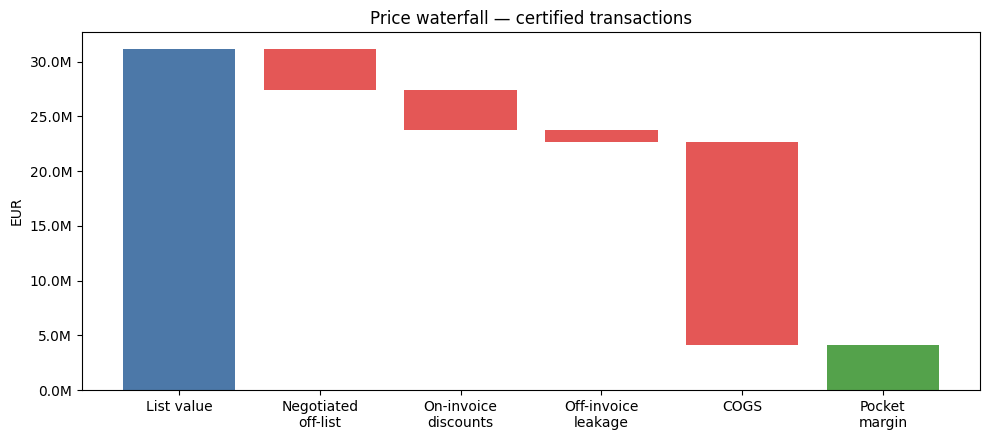

In [19]:
t = allr.totals
steps  = ["list_value","negotiated_off_list","on_invoice_discount","off_invoice_leakage","cogs","pocket_margin"]
labels = ["List value","Negotiated\noff-list","On-invoice\ndiscounts","Off-invoice\nleakage","COGS","Pocket\nmargin"]
vals   = [t[s] for s in steps]

fig, ax = plt.subplots(figsize=(10, 4.5))
running = 0
for i, (lab, v) in enumerate(zip(labels, vals)):
    if i == 0:
        ax.bar(lab, v, color="#4C78A8"); running = v
    elif i == len(vals) - 1:
        ax.bar(lab, v, color="#54A24B")
    else:
        running -= v
        ax.bar(lab, v, bottom=running, color="#E45756")
ax.set_ylabel("EUR"); ax.set_title("Price waterfall — certified transactions")
ax.yaxis.set_major_formatter(lambda x, p: f"{x/1e6:.1f}M")
plt.tight_layout(); plt.show()

## 8. What I take into Week 2

1. **`net_amount` is mislabelled relative to convention** — it nets off-invoice, not
   on-invoice. Confirm with the mentor; until then the engine computes from the discount
   edges and never trusts `net_amount`.
2. **24% of transactions (170/700) are not fully decomposable** because 1 product lacks a list
   price and 2 lack a unit cost. Small counts, wide blast radius. They are reported as
   UNAVAILABLE and excluded from certified totals — never zeroed.
3. **Price realisation ≈ 73%** of list on the certified book, with off-invoice leakage
   ≈ 3.6% of list on top of 11.8% on-invoice discount. Consistent with the 15–20%
   leakage the Brief describes.
4. **~17 deals per customer** — thin. Confirms the Week 5 need for hierarchical shrinkage.
5. **Channel cost-to-serve and commission are unused so far.** Whether they belong inside
   pocket margin is a definition to agree, not to assume. Week 2 design question.